In [1]:
import pandas as pd

# 1. Load and merge Accident files
accident = pd.read_csv("FARS2024NationalCSV/accident.csv", low_memory=False)
acc_aux = pd.read_csv("FARS2024NationalAuxiliaryCSV/ACC_AUX.CSV", low_memory=False)

merged_acc = pd.merge(accident, acc_aux, on=["STATE", "ST_CASE"], how="inner")

# 2. Load and merge Vehicle files
vehicle = pd.read_csv("FARS2024NationalCSV/vehicle.csv", low_memory=False)
veh_aux = pd.read_csv("FARS2024NationalAuxiliaryCSV/VEH_AUX.CSV", low_memory=False)

merged_veh = pd.merge(vehicle, veh_aux, on=["STATE", "ST_CASE", "VEH_NO"], how="inner")

XGBoost not installed. Run 'pip install xgboost shap' for gradient boosting and SHAP explanations.
Loading FARS datasets into Pandas...

Training Random Forest...
--- Random Forest Performance ---
ROC-AUC Score: 0.7487
PR-AUC Score:  0.7221
              precision    recall  f1-score   support

           0       0.66      0.87      0.75      9815
           1       0.73      0.44      0.55      7851

    accuracy                           0.68     17666
   macro avg       0.70      0.66      0.65     17666
weighted avg       0.69      0.68      0.66     17666



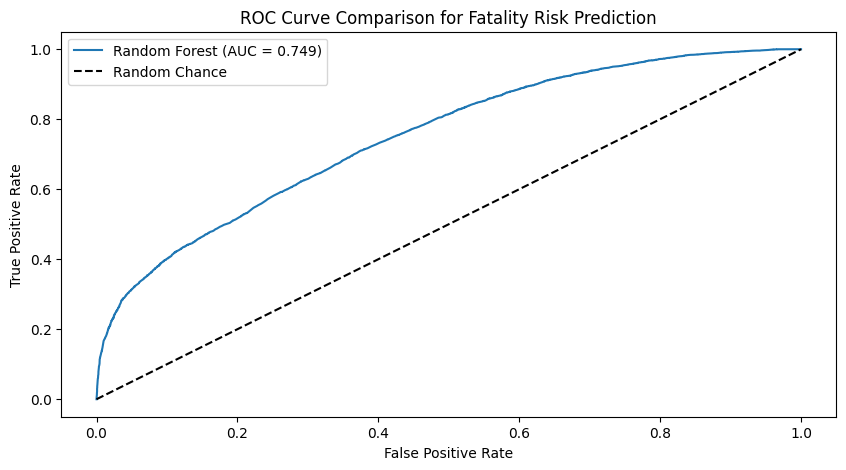

/var/folders/rn/yzd7dyjs6dq3pf50qjtn1z9d2qvxmx/T/ipykernel_8826/3288075727.py:160: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_imp, x="Importance", y="Feature", palette="viridis")


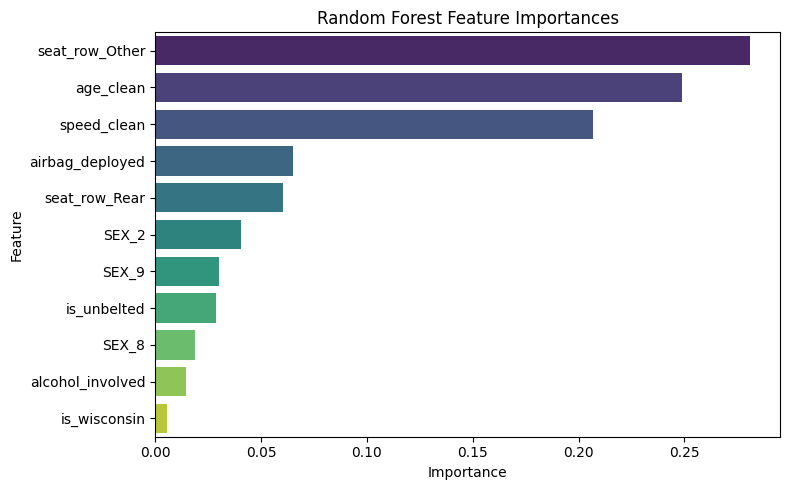


[Random Forest] Predicted Mean Fatality Risk:
  - Wisconsin:        45.05%
  - Rest of Nation:   44.43%


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.ensemble import RandomForestClassifier

# Modern Gradient Boosting
try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("XGBoost not installed. Run 'pip install xgboost shap' for gradient boosting and SHAP explanations.")

try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

# ---------------`------------------------------------------
# 1. DATA LOADING & WRANGLING
# ---------------------------------------------------------
print("Loading FARS datasets into Pandas...")
person = pd.read_csv("FARS2024NationalCSV/person.csv", low_memory=False)
vehicle = pd.read_csv("FARS2024NationalCSV/vehicle.csv", low_memory=False)

# Optional: Load driver impairment data to create an alcohol involvement flag
try:
    drimpair = pd.read_csv("FARS2024NationalCSV/drimpair.csv", low_memory=False)
    # FARS impairment codes: 1-4 indicate alcohol/drug/chemical impairment
    impaired_cases = set(drimpair[drimpair['DRIMPAIR'].isin([1, 2, 3, 4])]['ST_CASE'])
except FileNotFoundError:
    impaired_cases = set()

# Merge Person level with Vehicle level context
df = person.merge(
    vehicle[['ST_CASE', 'VEH_NO', 'BODY_TYP', 'MOD_YEAR', 'TRAV_SP']], 
    on=['ST_CASE', 'VEH_NO'], 
    how='left'
)

# ---------------------------------------------------------
# 2. FEATURE ENGINEERING & TARGET CREATION
# ---------------------------------------------------------
# Target: 1 if Fatal Injury (INJ_SEV == 4), 0 otherwise
df['target'] = (df['INJ_SEV'] == 4).astype(int)

# Wisconsin vs. National Flag
df['is_wisconsin'] = (df['STATE'] == 55).astype(int)

# Restraint usage: In FARS, REST_USE == 0 or 7 denotes unbelted; 1-4 lap/shoulder belt
df['is_unbelted'] = df['REST_USE'].isin([0, 7, 99]).astype(int)

# Airbag deployment flag: 1-9 indicate deployment
df['airbag_deployed'] = df['AIR_BAG'].between(1, 9).astype(int)

# Seating position: 11-13 front row, 21-23 second row
df['seat_row'] = np.where(df['SEAT_POS'].between(11, 13), 'Front', 
                          np.where(df['SEAT_POS'].between(21, 23), 'Rear', 'Other')
                          )

# Alcohol-involved crash flag
df['alcohol_involved'] = df['ST_CASE'].isin(impaired_cases).astype(int)

# Clean continuous fields (FARS uses 998/999 for unknown speed/age)
df['age_clean'] = np.where(df['AGE'] < 99, df['AGE'], np.nan)
df['speed_clean'] = np.where(df['TRAV_SP'] < 997, df['TRAV_SP'], np.nan)

# Fill NaNs with median values for ML input
df['age_clean'] = df['age_clean'].fillna(df['age_clean'].median())
df['speed_clean'] = df['speed_clean'].fillna(df['speed_clean'].median())

# Selected Model Features
numeric_features = ['age_clean', 'speed_clean', 'is_unbelted', 'airbag_deployed', 'alcohol_involved', 'is_wisconsin']
categorical_features = ['SEX', 'seat_row']

features = numeric_features + categorical_features
X = df[features]
y = df['target']

# ---------------------------------------------------------
# 3. TRAIN / TEST SPLIT & PIPELINE PREPROCESSING
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

# Transform data for training
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Get feature names post one-hot encoding
cat_encoded_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features))
all_feature_names = numeric_features + cat_encoded_names

# ---------------------------------------------------------
# 4. MODEL TRAINING & COMPARISON (Random Forest vs XGBoost)
# ---------------------------------------------------------
models = {
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
}

if HAS_XGBOOST:
    models["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.05, random_state=42, n_jobs=-1)

results = {}

plt.figure(figsize=(10, 5))

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_prep, y_train)
    
    y_pred = model.predict(X_test_prep)
    y_proba = model.predict_proba(X_test_prep)[:, 1]
    
    auc_roc = roc_auc_score(y_test, y_proba)
    auc_pr = average_precision_score(y_test, y_proba)
    
    results[name] = {"model": model, "auc_roc": auc_roc, "auc_pr": auc_pr}
    
    print(f"--- {name} Performance ---")
    print(f"ROC-AUC Score: {auc_roc:.4f}")
    print(f"PR-AUC Score:  {auc_pr:.4f}")
    print(classification_report(y_test, y_pred))
    
    # Plot ROC Curves
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_roc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison for Fatality Risk Prediction")
plt.legend()
plt.show()

# ---------------------------------------------------------
# 5. FEATURE IMPORTANCE & SHAP EXPLANATIONS
# ---------------------------------------------------------
rf_model = results["Random Forest"]["model"]
importances = rf_model.feature_importances_

df_imp = pd.DataFrame({"Feature": all_feature_names, "Importance": importances})
df_imp = df_imp.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=df_imp, x="Importance", y="Feature", palette="viridis")
plt.title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()

# SHAP Analysis for Local / Global Explainability
if HAS_SHAP and HAS_XGBOOST:
    print("\nComputing SHAP values for XGBoost model...")
    explainer = shap.TreeExplainer(results["XGBoost"]["model"])
    shap_values = explainer(X_test_prep)
    
    # Summary plot showing how features drive probability up/down
    shap.summary_plot(shap_values, X_test_prep, feature_names=all_feature_names)

# ---------------------------------------------------------
# 6. WISCONSIN VS. REST OF NATION INFERENCE
# ---------------------------------------------------------
wi_mask = X_test['is_wisconsin'] == 1
national_mask = X_test['is_wisconsin'] == 0

for name, res in results.items():
    m = res["model"]
    wi_proba = m.predict_proba(X_test_prep[wi_mask])[:, 1]
    nat_proba = m.predict_proba(X_test_prep[national_mask])[:, 1]
    
    print(f"\n[{name}] Predicted Mean Fatality Risk:")
    print(f"  - Wisconsin:        {wi_proba.mean() * 100:.2f}%")
    print(f"  - Rest of Nation:   {nat_proba.mean() * 100:.2f}%")